# Quantum Music — Name 1 : circuits et théorie
**Notebook de test** : imports, circuit 1 qubit, circuit 2 qubits (Bell), nombre de shots interactif, petits tests.

## 0. Installation (à faire une seule fois, dans le terminal)


```bash
pip install qiskit qiskit-aer matplotlib numpy scipy ipywidgets pylatexenc notebook
```

| Paquet | Rôle |
|---|---|
| `qiskit` | construire les circuits, calculer le statevector |
| `qiskit-aer` | simulateur avec échantillonnage (shots) et, plus tard, modèles de bruit |
| `matplotlib`, `numpy`, `scipy` | figures, calculs, statistiques |
| `ipywidgets` | curseurs interactifs dans le notebook |
| `pylatexenc` | dessin des circuits avec `draw("mpl")` |

In [12]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

import ipywidgets as widgets
from IPython.display import display

print("Qiskit      :", qiskit.__version__)
print("Qiskit Aer  :", qiskit_aer.__version__)
print("NumPy       :", np.__version__)
print("Imports OK ✅")

Qiskit      : 2.3.0
Qiskit Aer  : 0.17.2
NumPy       : 2.1.2
Imports OK ✅


## 1. Fonctions bases 

Rappels (pour moi) :
- **statevector** : probabilités *exactes* (pas de hasard) = la vérité théorique ;
- **shots** : on exécute le circuit N fois, chaque exécution donne *un* résultat → fluctuations en 1/√N.

⚠️ **Convention de Qiskit LITTLE-ENDIAN** : le qubit 0 est le bit le plus à **droite**. Il faut garder cette convention en tête.

In [ ]:
SIMULATOR = AerSimulator()

# Mapping bitstring -> note (slides du kickoff) 
NOTES_1Q = {"0": "Do", "1": "Ré"}
NOTES_2Q = {"00": "Do", "01": "Ré", "10": "Mi", "11": "Fa"}
NOTES = {1: NOTES_1Q, 2: NOTES_2Q}

# Distributions théoriques, écrites à la main (pas lues du simulateur)
THEORY = {
    "hadamard": {"0": 0.5, "1": 0.5},
    "bell": {"00": 0.5, "01": 0.0, "10": 0.0, "11": 0.5},
}

In [14]:
#circuit building
def build_hadamard(measure=True):
    qc = QuantumCircuit(1, 1 if measure else 0, name="hadamard")
    qc.h(0)
    if measure:
        qc.measure(0, 0)
    return qc


def build_bell(measure=True):
    qc = QuantumCircuit(2, 2 if measure else 0, name="bell")
    qc.h(0)
    qc.cx(0, 1)
    if measure:
        qc.measure([0, 1], [0, 1])
    return qc


def show_circuit(qc):
    """Dessine le circuit (matplotlib si possible, sinon texte)."""
    try:
        fig = qc.draw("mpl")
        display(fig)
        plt.close(fig)
    except Exception as e:
        print(f"(dessin matplotlib indisponible : {e}) -> version texte :")
        print(qc.draw("text"))


def exact_probabilities(circuit):
    """Probabilités exactes via le statevector"""
    qc = circuit.remove_final_measurements(inplace=False)
    probs = Statevector.from_instruction(qc).probabilities_dict()
    n = qc.num_qubits
    keys = [format(i, f"0{n}b") for i in range(2 ** n)]
    return {k: float(probs.get(k, 0.0)) for k in keys}


def run_counts(circuit, shots=1000, seed=None):
    """Exécute le circuit `shots` fois -> dict {bitstring: nombre d'occurrences}."""
    tqc = transpile(circuit, SIMULATOR)
    result = SIMULATOR.run(tqc, shots=shots, seed_simulator=seed).result()
    return dict(result.get_counts())


def run_samples(circuit, shots=16, seed=None):
    """Exécute le circuit et renvoie les résultats shot par shot, dans l'ordre."""
    tqc = transpile(circuit, SIMULATOR)
    result = SIMULATOR.run(tqc, shots=shots, seed_simulator=seed, memory=True).result()
    return result.get_memory()

In [15]:
#THEORICAL VALUES
def std_error(p, n):
    """Écart-type de la fréquence observée : sqrt(p(1-p)/N)."""
    return float(np.sqrt(p * (1 - p) / n))


def wilson_interval(k, n, z=1.96):
    """Intervalle de confiance de Wilson (95 % par défaut) pour une proportion k/n.
    Contrairement à l'intervalle normal, il reste utile pour p proche de 0 ou 1."""
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    demi = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return (max(0.0, centre - demi), min(1.0, centre + demi))


def tvd(p, q):
    """Distance de variation totale entre deux distributions (dicts)."""
    keys = set(p) | set(q)
    return 0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in keys)

In [16]:
#PLOT
def plot_counts(counts, theory, title="", ax=None):
    """Frequency histogram with Wilson error bars and theoretical value."""    
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.5))
    keys = list(theory.keys())
    notes = NOTES[len(keys[0])]
    n = sum(counts.values())
    k = np.array([counts.get(key, 0) for key in keys])
    freq = k / n
    ci = np.array([wilson_interval(int(ki), n) for ki in k])
    yerr = np.clip(np.vstack([freq - ci[:, 0], ci[:, 1] - freq]), 0, None)
    x = np.arange(len(keys))
    ax.bar(x, freq, yerr=yerr, capsize=5, alpha=0.7, label="mesure (IC Wilson 95 %)")
    ax.scatter(x, [theory[key] for key in keys], marker="_", s=900, color="black",
               linewidths=2, label="theory", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{key}\n{notes[key]}" for key in keys])
    ax.set_ylim(0, 1)
    ax.set_ylabel("frequency")
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax

## 2. Un qubit : porte de Hadamard → deux notes

|0⟩ → H → (|0⟩ + |1⟩)/√2, donc P(0) = P(1) = 50 % : `0 → Do`, `1 → Ré`.

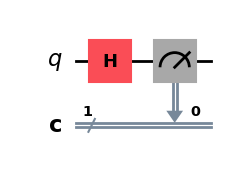

In [17]:
qc1 = build_hadamard()
show_circuit(qc1)

Exacts Probabilities : {'0': 0.4999999999999999, '1': 0.4999999999999999}
Counts (1000 shots) : {'0': 514, '1': 486}


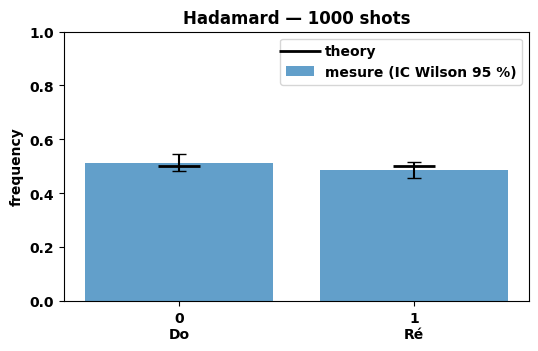

In [18]:
# Probabilités exactes
print("Exacts Probabilities :", exact_probabilities(qc1))

# Mesures avec 1000 shots
shots = 1000
counts1 = run_counts(qc1, shots=shots, seed=42)
print(f"Counts ({shots} shots) :", counts1)

plot_counts(counts1, THEORY["hadamard"], title=f"Hadamard — {shots} shots")
plt.show()

## 3. Deux qubits : circuit de Bell → 4 notes possibles

|00⟩ → H(q₀) → (|00⟩ + |10⟩)/√2 → CNOT(q₀→q₁) → (|00⟩ + |11⟩)/√2.
Seuls `00 → Do` et `11 → Fa` apparaissent, chacun à 50 % ; `01 → Ré` et `10 → Mi` sont à 0 %.

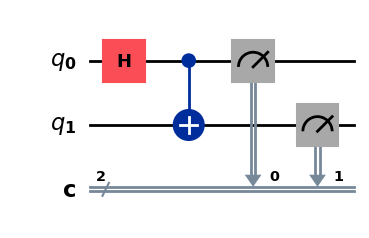

In [19]:
qc2 = build_bell()
show_circuit(qc2)

Amplitudes [00, 01, 10, 11] : [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]   (1/√2 ≈ 0.7071)
Probabilités exactes        : {'00': 0.4999999999999999, '01': 0.0, '10': 0.0, '11': 0.4999999999999999}
Counts (1000 shots)         : {'11': 490, '00': 510}


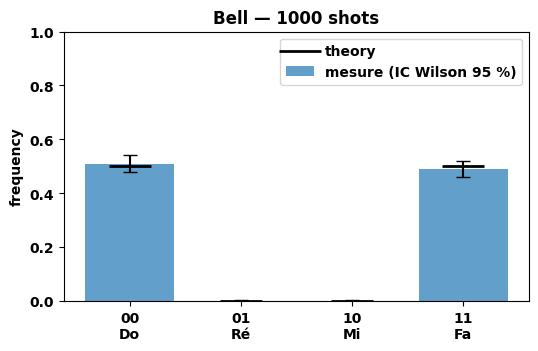

In [20]:
# Le statevector : amplitudes dans l'ordre [00, 01, 10, 11]
sv = Statevector.from_instruction(build_bell(measure=False))
print("Amplitudes [00, 01, 10, 11] :", np.round(sv.data, 4), "  (1/√2 ≈ 0.7071)")
print("Probabilités exactes        :", exact_probabilities(qc2))

counts2 = run_counts(qc2, shots=1000, seed=42)
print("Counts (1000 shots)         :", counts2)

plot_counts(counts2, THEORY["bell"], title="Bell — 1000 shots")
plt.show()

## 4. Un shot = une exécution = une note

`run_counts` garde seulement le total par issue. `run_samples` garde l'**ordre** des résultats : c'est cette séquence qui deviendra la mélodie (travail de Name 3).

In [21]:
samples = run_samples(build_bell(), shots=16, seed=7)
print("Bitstrings :", samples)
print("Mélodie    :", " ".join(NOTES_2Q[s] for s in samples))

Bitstrings : ['11', '11', '00', '00', '00', '11', '11', '11', '11', '00', '11', '00', '11', '00', '00', '11']
Mélodie    : Fa Fa Do Do Do Fa Fa Fa Fa Do Fa Do Fa Do Do Fa


## 5. Nombre de shots interactif

Bouge le curseur : avec peu de shots les fluctuations sont grandes, avec beaucoup de shots les fréquences se rapprochent de la théorie. Les barres d'erreur sont des intervalles de Wilson à 95 %.
(Si les curseurs n'apparaissent pas : `pip install ipywidgets`, puis relancer Jupyter.)

In [22]:
def experiment(circuit_name="bell", shots=1000, seed=42):
    qc = build_hadamard() if circuit_name == "hadamard" else build_bell()
    theory = THEORY[circuit_name]
    counts = run_counts(qc, shots, seed)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    plot_counts(counts, theory, title=f"{circuit_name} — {shots} shots", ax=ax)
    plt.show()

    notes = NOTES[qc.num_qubits]
    print(f"{'issue':<7}{'note':<6}{'counts':>8}{'fréq.':>9}    IC Wilson 95 %      théorie")
    for key, p_th in theory.items():
        k = counts.get(key, 0)
        lo, hi = wilson_interval(k, shots)
        print(f"{key:<7}{notes[key]:<6}{k:>8}{k / shots:>9.3f}    [{lo:.3f}, {hi:.3f}]    {p_th:>8.3f}")
    freqs = {key: counts.get(key, 0) / shots for key in theory}
    print(f"\nσ théorique (p = 0,5) = {std_error(0.5, shots):.4f}"
          f"   |   TVD(mesure, théorie) = {tvd(freqs, theory):.4f}")


widgets.interact(
    experiment,
    circuit_name=widgets.Dropdown(options=["hadamard", "bell"], value="bell", description="Circuit"),
    shots=widgets.SelectionSlider(options=[10, 50, 100, 500, 1000, 5000, 10000, 100000],
                                  value=1000, description="Shots", continuous_update=False),
    seed=widgets.IntSlider(min=0, max=100, step=1, value=42, description="Seed",
                           continuous_update=False),
);

interactive(children=(Dropdown(description='Circuit', index=1, options=('hadamard', 'bell'), value='bell'), Se…

## 6. L'erreur statistique décroît en 1/√N

On répète l'expérience Hadamard plusieurs fois pour chaque N et on mesure l'écart quadratique moyen entre la fréquence de "0" et 0,5. En échelle log-log, on doit suivre la droite théorique de pente −1/2 : σ = 0,5/√N.

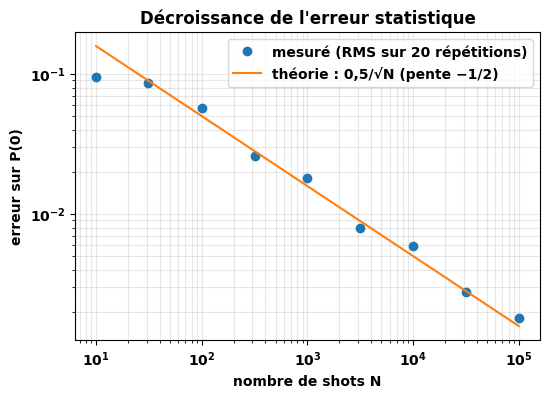

In [ ]:
Ns = np.logspace(1, 5, 9).astype(int)     # 10 ... 100000
n_rep = 20
rms = []
qc_h = build_hadamard()
for i, N in enumerate(Ns):
    devs = []
    for r in range(n_rep):
        c = run_counts(qc_h, int(N), seed=1000 * i + r)
        devs.append(c.get("0", 0) / N - 0.5)
    rms.append(np.sqrt(np.mean(np.square(devs))))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, rms, "o", label=f"mesuré (RMS sur {n_rep} répétitions)")
ax.loglog(Ns, [std_error(0.5, N) for N in Ns], "-", label="théorie : 0,5/√N (pente -1/2)")
ax.set_xlabel("nombre de shots N")
ax.set_ylabel("erreur sur P(0)")
ax.set_title("Décroissance de l'erreur statistique")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

## 7. Petits tests

en mode test unitaires

In [27]:
def test_hadamard_structure():
    qc = build_hadamard()
    ops = qc.count_ops()
    assert qc.num_qubits == 1, "Hadamard circuit must contain 1 qubit"
    assert ops.get("h", 0) == 1 and ops.get("measure", 0) == 1, \
        f"unexpected operations: {dict(ops)}"


def test_bell_structure():
    qc = build_bell()
    ops = qc.count_ops()
    assert qc.num_qubits == 2, "Bell circuit must contain 2 qubits"
    assert ops.get("h", 0) == 1 and ops.get("cx", 0) == 1 and ops.get("measure", 0) == 2, \
        f"unexpected operations: {dict(ops)}"

    gate_sequence = [inst.operation.name for inst in qc.data if inst.operation.name != "measure"]
    assert gate_sequence == ["h", "cx"], \
        f"incorrect gate ordering: {gate_sequence}"


def test_bell_statevector():
    sv = Statevector.from_instruction(build_bell(measure=False))
    target_state = Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2))
    assert sv.equiv(target_state), \
        "Bell statevector must be (|00> + |11>)/√2"


def test_exact_probabilities_match_theory():
    for circuit_name, builder in [("hadamard", build_hadamard), ("bell", build_bell)]:
        exact = exact_probabilities(builder())
        for outcome, p_theory in THEORY[circuit_name].items():
            assert np.isclose(exact[outcome], p_theory), \
                f"{circuit_name}: P({outcome}) = {exact[outcome]} instead of {p_theory}"


def test_seed_reproducible():
    counts_a = run_counts(build_bell(), 1000, seed=123)
    counts_b = run_counts(build_bell(), 1000, seed=123)
    assert counts_a == counts_b, "same seed should produce identical counts"


def test_counts_sum_to_shots():
    for shots in (10, 1000, 4321):
        assert sum(run_counts(build_bell(), shots, seed=1).values()) == shots, \
            f"count total differs from {shots}"


def test_bell_forbidden_outcomes_absent():
    counts = run_counts(build_bell(), 5000, seed=5)
    assert counts.get("01", 0) == 0 and counts.get("10", 0) == 0, \
        f"forbidden outcomes observed: {counts}"


def test_convergence_within_4_sigma():
    N = 20000
    p_hat = run_counts(build_hadamard(), N, seed=11).get("0", 0) / N
    assert abs(p_hat - 0.5) < 4 * std_error(0.5, N), \
        f"p̂ = {p_hat}"


def test_std_error_value():
    assert np.isclose(std_error(0.5, 1000), 0.015811, atol=1e-5), \
        "σ(p=0.5, N=1000) ≈ 0.0158"


def test_wilson_zero_count():
    lo, hi = wilson_interval(0, 1000)
    assert lo < 1e-12 and hi > 0, \
        f"Wilson interval for k=0: [{lo}, {hi}]"


def test_wilson_coverage():
    rng = np.random.default_rng(0)
    ks = rng.binomial(1000, 0.5, size=2000)
    coverage = np.mean([
        wilson_interval(int(k), 1000)[0] <= 0.5 <= wilson_interval(int(k), 1000)[1]
        for k in ks
    ])
    assert 0.93 < coverage < 0.97, \
        f"Wilson coverage = {coverage:.3f} (expected ≈ 0.95)"


def test_tvd():
    noisy_distribution = {
        "00": 0.41,
        "01": 0.09,
        "10": 0.09,
        "11": 0.41,
    }  # 10% bit-flip example from the slide

    assert np.isclose(tvd(THEORY["bell"], noisy_distribution), 0.18), \
        "expected TVD = 0.18"


tests = [
    test_function
    for name, test_function in globals().items()
    if name.startswith("test_") and callable(test_function)
]

failed = 0

for test_function in tests:
    try:
        test_function()
        print(f"✅ {test_function.__name__}")
    except AssertionError as err:
        failed += 1
        print(f"❌ {test_function.__name__}: {err}")

print(
    f"\n{len(tests) - failed}/{len(tests)} tests passed"
    + (" 🎉" if failed == 0 else " — fixes required")
)

✅ test_hadamard_structure
✅ test_bell_structure
✅ test_bell_statevector
✅ test_exact_probabilities_match_theory
✅ test_seed_reproducible
✅ test_counts_sum_to_shots
✅ test_bell_forbidden_outcomes_absent
✅ test_convergence_within_4_sigma
✅ test_std_error_value
✅ test_wilson_zero_count
✅ test_wilson_coverage
✅ test_tvd
✅ test_tvd

13/13 tests passed 🎉
